# Are Exoplanet Transit Predictions Going Stale?
### Final project — Checkpoint 1: Data in Hand

**Name:** Jason Bogovich
**Date:** November 20, 2026
**Course:** Emerging Technology

## The question

Astronomers schedule telescope time, including on JWST, around the predicted moment a planet crosses in front of its star (a *transit*). Each prediction comes from a published starting time and orbital period, and any small error in the period adds up with every orbit.

**Driving question:** For known transiting exoplanets, how far have the published transit predictions drifted from what NASA's TESS telescope has recently observed, and can the drift be predicted from properties such as how long ago the planet was last measured?

**Why TESS?** TESS is a NASA space telescope with wide-angle cameras that stare at one strip of sky for about 27 days at a time and have covered most of the sky repeatedly since 2018. For this project that means nearly every bright transiting planet has been observed several times, years apart, by the same instrument and clock, with whole transits recorded and no gaps for daylight or weather.

## The three datasets

| # | Dataset | Source | One row is | File |
|---|---|---|---|---|
| 1 | Planet list with published predictions | [NASA Exoplanet Archive](https://exoplanetarchive.ipac.caltech.edu), Planetary Systems Composite table | one planet | `data/planets.csv` |
| 2 | Catalogue of available TESS observations | [MAST archive](https://archive.stsci.edu) search service | one star observed for one ~27-day TESS "sector" | `data/tess_inventory.csv` |
| 3 | TESS light curves (brightness over time) | MAST archive, 2-minute light curve files | one brightness measurement | `data/lightcurves/*.csv` |

Each is downloaded by a short script in this repository (`fetch_planets.py`, `fetch_tess_inventory.py`, `fetch_lightcurves.py`). All three sources are public and need no account or API key.

*Use of AI: I used an AI assistant (Claude) to help find the data services and to draft and check the code. The topic and questions are my own.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
INK, MUTED, ACCENT = "#2b2f33", "#8a9099", "#b3261e"

## Dataset 1 — The planets and their published predictions

**How it was collected.** `fetch_planets.py` sends one query to the Exoplanet Archive and keeps planets that TESS can time well:

- the planet transits its star,
- the dip is at least 0.5% of the star's light,
- the star is brighter than TESS magnitude 12,
- the orbit is shorter than 10 days, so several transits fall in each 27-day sector.

In [2]:
planets = pd.read_csv("data/planets.csv")
print(f"{len(planets)} planets, {planets.shape[1]} columns, retrieved {planets['retrieved'].iloc[0]}")
planets.head(3)

349 planets, 24 columns, retrieved 2026-11-20


,pl_name,hostname,tic_id,disc_year,disc_facility,pl_orbper,pl_orbpererr1,pl_orbpererr2,pl_orbper_ref,pl_tranmid,...,pl_trandep,pl_trandur,pl_rade,pl_bmasse,st_teff,sy_tmag,ra,dec,tic,retrieved
0,BD+05 4868 A b,BD+05 4868 A,TIC 466376085,2025,Transiting Exoplanet Survey Satellite (TESS),1.271869,0.000001,-0.000001,Hon et al. 2025,2.460556e+06,...,1.400,NaN,NaN,6.20,4596.0,9.1886,326.861404,6.605319,466376085,2026-11-20
1,BD-14 3065 b,BD-14 3065 A,TIC 293607057,2024,Transiting Exoplanet Survey Satellite (TESS),4.288973,0.000005,-0.000005,Šubjak et al. 2024,2.459313e+06,...,0.649,3.08600,21.590,3932.00,6935.0,10.6311,153.669669,-15.642837,293607057,2026-11-20
2,CoRoT-2 b,CoRoT-2,TIC 391958006,2008,CoRoT,1.742994,0.000001,-0.000001,Gillon et al. 2010,2.454238e+06,...,2.750,2.26704,16.432,1102.82,5625.0,11.6659,291.777046,1.383663,391958006,2026-11-20


In [3]:
planets.dtypes.to_frame("dtype").T

,pl_name,hostname,tic_id,disc_year,disc_facility,pl_orbper,pl_orbpererr1,pl_orbpererr2,pl_orbper_ref,pl_tranmid,...,pl_trandep,pl_trandur,pl_rade,pl_bmasse,st_teff,sy_tmag,ra,dec,tic,retrieved
dtype,str,str,str,int64,str,float64,float64,float64,str,float64,...,float64,float64,float64,float64,float64,float64,float64,float64,int64,str


**The columns that matter**

| Column | Meaning | Unit |
|---|---|---|
| `pl_name`, `hostname`, `tic` | planet, its star, and the star's number in the TESS catalogue | text / integer |
| `pl_tranmid`, `pl_tranmiderr1` | published reference transit time and its uncertainty | days (Julian Date) |
| `pl_orbper`, `pl_orbpererr1` | published orbital period and its uncertainty | days |
| `pl_tranmid_systemref` | which clock the transit time uses (categorical) | text |
| `pl_tranmid_ref`, `pl_orbper_ref` | the paper each value came from | text |
| `pl_trandep`, `pl_trandur` | depth and length of the dip | % and hours |
| `sy_tmag` | brightness of the star as TESS sees it (smaller = brighter) | magnitude |
| `disc_facility`, `disc_year` | who discovered the planet and when (categorical / integer) | text / year |

In [4]:
key = ["pl_orbper", "pl_orbpererr1", "pl_tranmiderr1", "pl_trandep", "pl_trandur", "sy_tmag", "disc_year"]
display(planets[key].describe().round(5).T)

print("Missing values:", planets.isna().sum()[lambda s: s > 0].to_dict())
print("\nClock used for the published transit time:")
print(planets["pl_tranmid_systemref"].value_counts().to_string())
same = (planets["pl_orbper_ref"] == planets["pl_tranmid_ref"]).mean()
print(f"\nPeriod and transit time come from the same paper for {100 * same:.0f}% of planets")

,count,mean,std,min,25%,50%,75%,max
pl_orbper,349.0,3.72149,1.64996,0.67247,2.70579,3.55395,4.43318,9.62468
pl_orbpererr1,349.0,0.00001,0.00006,0.00000,0.00000,0.00000,0.00001,0.00100
pl_tranmiderr1,348.0,0.00050,0.00260,0.00000,0.00012,0.00022,0.00040,0.04800
pl_trandep,349.0,1.16270,0.61799,0.50900,0.74930,1.04000,1.39700,8.20000
pl_trandur,348.0,3.21098,1.20408,0.78576,2.34155,3.03613,3.85429,11.04000
sy_tmag,349.0,10.73915,0.98113,6.84810,10.18680,10.95710,11.50370,11.98240
disc_year,349.0,2016.74499,5.84727,1999.00000,2012.00000,2017.00000,2022.00000,2026.00000


Missing values: {'pl_tranmiderr1': 1, 'pl_tranmiderr2': 1, 'pl_trandur': 1, 'pl_rade': 1, 'pl_bmasse': 2}

Clock used for the published transit time:
pl_tranmid_systemref
BJD-TDB    209
BJD         86
HJD         17
BJD-UTC     15
HJD-UTC     15
JD           7

Period and transit time come from the same paper for 75% of planets


**How uncertain is each prediction today?** A prediction for transit number *N* after the reference time has uncertainty

$$\sigma_{\text{today}} = \sqrt{\sigma_{T_0}^2 + (N \cdot \sigma_P)^2}$$

so the period error is multiplied by the number of orbits since the reference time. This is the published, *claimed* uncertainty; so this project will measure the *actual* error.

In [5]:
TODAY_JD = pd.Timestamp("2026-11-20").to_julian_date()

planets["epoch_year"] = 2000 + (planets["pl_tranmid"] - 2451544.5) / 365.25          # calendar year of the reference transit
planets["orbits_since"] = (TODAY_JD - planets["pl_tranmid"]) / planets["pl_orbper"]
planets["claimed_error_min"] = 1440 * np.sqrt(planets["pl_tranmiderr1"].fillna(0) ** 2
                                              + (planets["orbits_since"] * planets["pl_orbpererr1"]) ** 2)

print(planets["claimed_error_min"].describe().round(1).to_string())
planets.nlargest(5, "claimed_error_min")[["pl_name", "epoch_year", "orbits_since", "pl_orbpererr1",
                                           "claimed_error_min", "pl_tranmid_ref"]].round(6)

count     349.0
mean       17.0
std        71.6
min         0.0
25%         1.7
50%         4.6
75%        10.9
max      1222.4


,pl_name,epoch_year,orbits_since,pl_orbpererr1,claimed_error_min,pl_tranmid_ref
103,Qatar-8 b,2018.251444,848.910537,0.00100,1222.431786,Alsubai et al. 2019
148,TOI-277 b,2020.740113,562.011417,0.00040,323.727832,Magliano et al. 2023
94,KELT-8 b,2017.637145,1041.297827,0.00016,239.915312,Kokori et al. 2023
179,TOI-4329 b,2019.768838,889.515792,0.00015,192.156995,Grunblatt et al. 2022
92,KELT-6 b,2015.535000,528.422099,0.00020,152.186352,Kokori et al. 2023


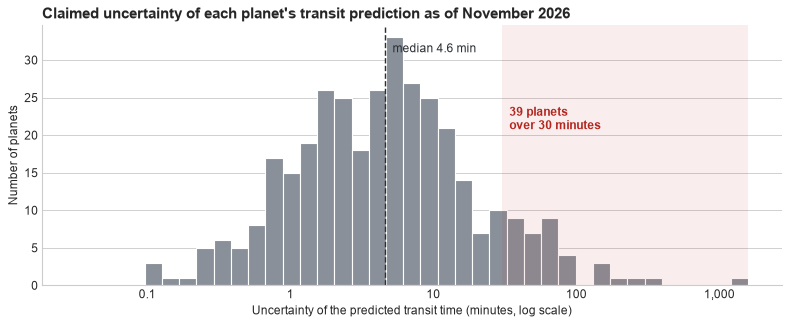

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.2))
bins = np.logspace(-1.5, 3.2, 40)
ax.hist(planets["claimed_error_min"], bins=bins, color=MUTED, edgecolor="white")
ax.set_xscale("log")
median = planets["claimed_error_min"].median()
ax.axvline(median, color=INK, linestyle="--", linewidth=1.3)
ax.text(median * 1.12, ax.get_ylim()[1] * 0.93, f"median {median:.1f} min", color=INK, va="top")
over_30 = (planets["claimed_error_min"] > 30).sum()
ax.axvspan(30, bins[-1], color=ACCENT, alpha=0.08, lw=0)
ax.text(34, ax.get_ylim()[1] * 0.6, f"{over_30} planets\nover 30 minutes", color=ACCENT, fontweight="bold")
ax.set_title("Claimed uncertainty of each planet's transit prediction as of November 2026")
ax.set_xlabel("Uncertainty of the predicted transit time (minutes, log scale)")
ax.set_ylabel("Number of planets")
ax.set_xticks([0.1, 1, 10, 100, 1000], ["0.1", "1", "10", "100", "1,000"])
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Most predictions claim to be good to a few minutes, but a tail of planets is uncertain by half an hour or more. Whether the claimed numbers are honest is what the TESS data will test.

## Dataset 2 — What TESS has observed

**How it was collected.** `fetch_tess_inventory.py` asks the MAST archive which 2-minute light curves exist for the 349 stars. Nothing large is downloaded; this is the catalogue that tells me what I can use.

In [7]:
inventory = pd.read_csv("data/tess_inventory.csv", parse_dates=["start_date", "end_date"])
print(f"{len(inventory):,} light curves for {inventory['tic'].nunique()} of {planets['tic'].nunique()} stars")
display(inventory.head(3))
inventory.dtypes.to_frame("dtype").T

1,865 light curves for 340 of 349 stars


,tic,sector,start_date,end_date,mast_uri
0,1003831,8,2019-02-02,2019-02-27,mast:TESS/product/tess2019032160000-s0008-0000...
1,1003831,34,2021-01-14,2021-02-08,mast:TESS/product/tess2021014023720-s0034-0000...
2,1003831,61,2023-01-18,2023-02-12,mast:TESS/product/tess2023018032328-s0061-0000...


,tic,sector,start_date,end_date,mast_uri
dtype,int64,int64,datetime64[us],datetime64[us],str


In [8]:
per_star = inventory.groupby("tic").agg(n_sectors=("sector", "count"), first_tess=("start_date", "min"),
                                        last_tess=("end_date", "max"))
print("Light curves per star:")
print(per_star["n_sectors"].describe().round(1).to_string())
print("\nMost recent TESS observation, by year:")
print(per_star["last_tess"].dt.year.value_counts().sort_index().to_string())

# Combine with the planet list: which planets have TESS data newer than their published prediction?
planets = planets.merge(per_star, left_on="tic", right_index=True, how="left")
planets["ref_year"] = planets["pl_tranmid_ref"].str.extract(r"(\d{4})\s*$").astype(float)   # year the prediction was published
planets["years_of_new_data"] = planets["last_tess"].dt.year - planets["ref_year"]
usable = planets[planets["years_of_new_data"] >= 1]
print(f"\n{planets['n_sectors'].isna().sum()} planets have no 2-minute TESS light curve.")
print(f"{len(usable)} planets have TESS data at least one year newer than their published prediction.")

Light curves per star:
count    340.0
mean       5.5
std        6.4
min        1.0
25%        2.0
50%        4.0
75%        6.0
max       43.0

Most recent TESS observation, by year:
last_tess
2020      3
2021      2
2022     20
2023     23
2024    127
2025     60
2026    105

9 planets have no 2-minute TESS light curve.
264 planets have TESS data at least one year newer than their published prediction.


## Dataset 3 — The light curves

**How it was collected.** MAST stores each light curve as a FITS file (the standard astronomy format, about 2 MB, 20 columns). `fetch_lightcurves.py` downloads the file, keeps the three columns this project needs, removes measurements NASA's pipeline flagged as bad, and saves a CSV. For this checkpoint I downloaded the most recent sector for three planets; the full set comes next.

| Column | Meaning | Unit |
|---|---|---|
| `time_btjd` | time of the measurement | days (BTJD = Barycentric Julian Date − 2,457,000) |
| `flux` | brightness of the star after NASA's systematics correction (`PDCSAP_FLUX`) | electrons per second |
| `flux_err` | uncertainty of that brightness | electrons per second |

In [9]:
SAMPLES = {"WASP-12 b": "data/lightcurves/WASP-12_b_s0072.csv",
           "Qatar-8 b": "data/lightcurves/Qatar-8_b_s0074.csv",
           "HAT-P-3 b": "data/lightcurves/HAT-P-3_b_s0076.csv"}
curves = {name: pd.read_csv(path) for name, path in SAMPLES.items()}

lc = curves["WASP-12 b"]
display(lc.head(3))
print(lc.dtypes.to_string())
pd.DataFrame({name: {"measurements": len(c), "days covered": c["time_btjd"].max() - c["time_btjd"].min(),
                     "median flux (e-/s)": c["flux"].median(),
                     "scatter (%)": 100 * (c["flux"] / c["flux"].median()).diff().std() / np.sqrt(2)}
              for name, c in curves.items()}).T.round(2)

,time_btjd,flux,flux_err
0,3261.791822,6084.89,12.68
1,3261.793211,6092.50,12.69
2,3261.794600,6063.00,12.66


time_btjd    float64
flux         float64
flux_err     float64


,measurements,days covered,median flux (e-/s),scatter (%)
WASP-12 b,15059.0,23.80,6108.62,0.18
Qatar-8 b,11870.0,26.70,7282.85,0.16
HAT-P-3 b,10608.0,27.08,8532.18,0.15


**Does the data show transits where the archive says they should be?** For each sample planet I mark the published predictions (reference time + whole numbers of periods) on the light curve. The time-system differences noted above are at most about a minute, too small to see at this scale.

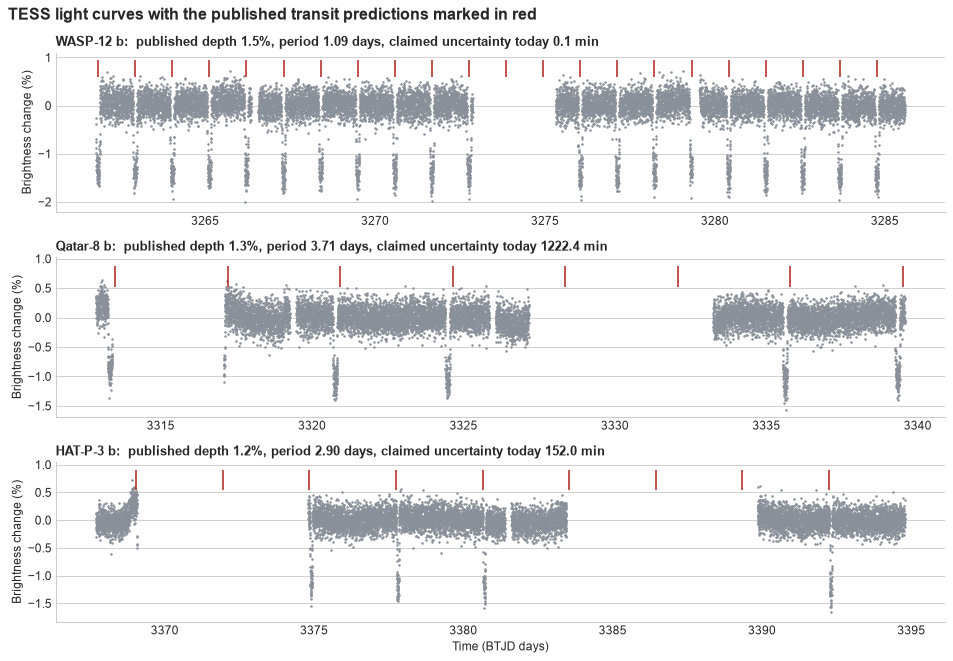

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8.4))
for ax, (name, c) in zip(axes, curves.items()):
    p = planets[planets["pl_name"] == name].iloc[0]
    t0 = p["pl_tranmid"] - 2457000                                   # published reference time, converted to BTJD
    n = np.arange(np.ceil((c["time_btjd"].min() - t0) / p["pl_orbper"]),
                  np.floor((c["time_btjd"].max() - t0) / p["pl_orbper"]) + 1)
    predicted = t0 + n * p["pl_orbper"]
    relative = 100 * (c["flux"] / c["flux"].median() - 1)
    ax.scatter(c["time_btjd"], relative, s=1.5, color=MUTED, rasterized=True)
    ax.vlines(predicted, relative.quantile(0.999), relative.quantile(0.999) + 0.35, color=ACCENT, linewidth=1.4)
    ax.set_ylim(relative.quantile(0.0005) - 0.3, relative.quantile(0.999) + 0.5)
    ax.set_ylabel("Brightness change (%)")
    ax.set_title(f"{name}:  published depth {p['pl_trandep']:.1f}%, period {p['pl_orbper']:.2f} days, "
                 f"claimed uncertainty today {p['claimed_error_min']:.1f} min", fontsize=11.5)
    ax.grid(axis="x", visible=False)
axes[-1].set_xlabel("Time (BTJD days)")
fig.suptitle("TESS light curves with the published transit predictions marked in red",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

The dips are where the archive says they should be for WASP-12 b and HAT-P-3 b. For Qatar-8 b, whose prediction has the largest claimed uncertainty in the list, the dips fall visibly earlier than the red marks. That is a first hint of the drift this project sets out to measure.

## Where this stands

**In hand:** 349 planets with their published predictions, a catalogue of 1,865 TESS light curves covering 340 of their stars, and three sample light curves in which the transits are visible.

**Issues found in the data that the analysis must handle**

- **Six different clocks.** The published transit times use several time systems (`BJD-TDB`, `BJD-UTC`, `HJD`, ...). These differ by up to about a minute, which matters when the errors I am measuring are a few minutes. TESS uses BJD-TDB.
- **Mixed sources.** The composite table picks each value separately, so for about a quarter of the planets the period and reference time come from different papers and may not be a matched pair. The archive's `ps` table keeps one paper's values together and may be the better source.
- **Gaps.** Each light curve has gaps where bad measurements were removed, so some transits are only partly observed.
- **Nine planets have no 2-minute TESS light curve** and will be dropped.

**Related work.** Professional teams have refreshed many of these predictions with TESS data, for example Ivshina & Winn (2022, 382 systems) and the ExoClock project (Kokori et al. 2023, 450 planets). Their published timing tables give me something to check my measurements against. This project repeats their approach independently, adds TESS data taken since, and tests the predictions the NASA archive shows by default.

**Next checkpoint (Analysis Plan):** measure the mid-time of each transit in one planet's light curve, compare it with the prediction, and justify the method before running it on every planet.